In [ ]:
import numpy as np

class LogisticRegression:

    def __init__(self, epochs=1000, lr=0.01, classification_threshold=0.5):
        # Parameters
        self.w = None
        self.b = None
        # Hyperparameters
        self.epochs = epochs    
        self.lr = lr
        self.classification_threshold = classification_threshold

    def sigmoid(self, z):
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        n, d = X.shape

        w = np.zeros(d)
        b = 0

        for epoch in range(self.epochs):
            y_pred = self.sigmoid(X @ w + b)
            error = y_pred - y
            dw = (1/n) * (X.T @ error)
            db = (1/n) * np.sum(error)
            w = w - self.lr * dw
            b = b - self.lr * db

        self.w = w
        self.b = b

    def predict(self, X):
        z = X @ self.w + self.b
        probabilities = self.sigmoid(z)
        return (probabilities >= self.classification_threshold).astype(int)

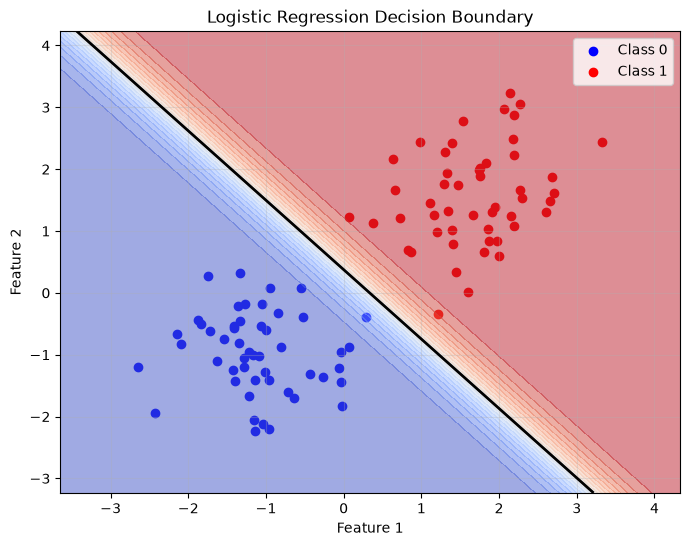

Accuracy: 100.00%


In [10]:
import matplotlib.pyplot as plt

# Create a simple 2D binary-classification dataset
rng = np.random.default_rng()
class_0 = rng.normal(loc=[-1.0, -1.0], scale=0.7, size=(50, 2))
class_1 = rng.normal(loc=[1.5, 1.5], scale=0.7, size=(50, 2))

X = np.vstack([class_0, class_1])
y = np.concatenate([np.zeros(len(class_0)), np.ones(len(class_1))])

# Train the model
model = LogisticRegression(epochs=5000, lr=0.1)
model.fit(X, y)

# Plot the data
plt.figure(figsize=(8, 6))
plt.scatter(X[y == 0, 0], X[y == 0, 1], color='blue', label='Class 0')
plt.scatter(X[y == 1, 0], X[y == 1, 1], color='red', label='Class 1')

# Plot the decision boundary using the sigmoid probabilities
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
Z = model.sigmoid(np.c_[xx.ravel(), yy.ravel()] @ model.w + model.b).reshape(xx.shape)

plt.contourf(xx, yy, Z, levels=20, cmap='coolwarm', alpha=0.5)
plt.contour(xx, yy, Z, levels=[0.5], colors='black', linewidths=2)
plt.title("Logistic Regression Decision Boundary")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Accuracy
predictions = model.predict(X)
accuracy = np.mean(predictions == y)
print(f"Accuracy: {accuracy:.2%}")